In [1]:
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import random

In [2]:
# Run this once to load the train and test data straight into a dataloader class
# that will provide the batches
batch_size_train = 64
batch_size_test = 1000
train_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST('/files/', train=True, download=True,
                             transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_train, shuffle=True)

test_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST('/files/', train=False, download=True,
                             transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_test, shuffle=True)

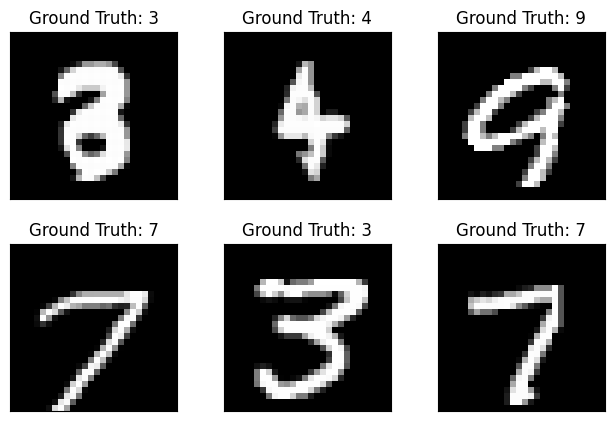

In [3]:
# Let's draw some of the training data
examples = enumerate(test_loader)
batch_idx, (example_data, example_targets) = next(examples)

fig = plt.figure()
for i in range(6):
  plt.subplot(2,3,i+1)
  plt.tight_layout()
  plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
  plt.title("Ground Truth: {}".format(example_targets[i]))
  plt.xticks([])
  plt.yticks([])
plt.show()

Define the network.  This is a more typical way to define a network than the sequential structure.  We define a class for the network, and define the parameters in the constructor.  Then we use a function called forward to actually run the network.  It's easy to see how you might use residual connections in this format.

In [4]:
from os import X_OK
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(1, 10, 5)
        self.pool1 = nn.MaxPool2d(2, 2)
        self.relu1 = nn.ReLU()
        self.conv2 = nn.Conv2d(10, 20, 5)
        self.dropout2d = nn.Dropout2d()
        self.pool2 = nn.MaxPool2d(2, 2)
        self.relu2 = nn.ReLU()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(320, 50)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(50, 10)
        self.softmax = nn.Softmax(dim=1)
    def forward(self, x):
        x = self.conv1(x)
        x = self.pool1(x)
        x = self.relu1(x)
        x = self.conv2(x)
        x = self.dropout2d(x)
        x = self.pool2(x)
        x = self.relu2(x)
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu3(x)
        x = self.fc2(x)
        x = self.softmax(x)
        return x

In [5]:
# He initialization of weights
def weights_init(layer_in):
  if isinstance(layer_in, nn.Linear):
    nn.init.kaiming_uniform_(layer_in.weight)
    layer_in.bias.data.fill_(0.0)

In [6]:
# Create network
model = Net()
# Initialize model weights
model.apply(weights_init)
# Define optimizer
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)

In [7]:
# Main training routine
def train(epoch):
  model.train()
  # Get each
  for batch_idx, (data, target) in enumerate(train_loader):
    optimizer.zero_grad()
    output = model(data)
    loss = F.nll_loss(output, target)
    loss.backward()
    optimizer.step()
    # Store results
    if batch_idx % 10 == 0:
      print('Train Epoch: {} [{}/{}]\tLoss: {:.6f}'.format(
        epoch, batch_idx * len(data), len(train_loader.dataset), loss.item()))

In [8]:
# Run on test data
def test():
  model.eval()
  test_loss = 0
  correct = 0
  with torch.no_grad():
    for data, target in test_loader:
      output = model(data)
      test_loss += F.nll_loss(output, target, size_average=False).item()
      pred = output.data.max(1, keepdim=True)[1]
      correct += pred.eq(target.data.view_as(pred)).sum()
  test_loss /= len(test_loader.dataset)
  print('\nTest set: Avg. loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
    test_loss, correct, len(test_loader.dataset),
    100. * correct / len(test_loader.dataset)))

In [11]:
# Get initial performance
test()
# Train for three epochs
n_epochs = 5
for epoch in range(1, n_epochs + 1):
  train(epoch)
  test()


Test set: Avg. loss: -0.5893, Accuracy: 5905/10000 (59%)

Train Epoch: 1 [0/60000]	Loss: -0.568253
Train Epoch: 1 [640/60000]	Loss: -0.491252
Train Epoch: 1 [1280/60000]	Loss: -0.573750
Train Epoch: 1 [1920/60000]	Loss: -0.629007
Train Epoch: 1 [2560/60000]	Loss: -0.637722
Train Epoch: 1 [3200/60000]	Loss: -0.567118
Train Epoch: 1 [3840/60000]	Loss: -0.536580
Train Epoch: 1 [4480/60000]	Loss: -0.605053
Train Epoch: 1 [5120/60000]	Loss: -0.377624
Train Epoch: 1 [5760/60000]	Loss: -0.598812
Train Epoch: 1 [6400/60000]	Loss: -0.522286
Train Epoch: 1 [7040/60000]	Loss: -0.677492
Train Epoch: 1 [7680/60000]	Loss: -0.591770
Train Epoch: 1 [8320/60000]	Loss: -0.468633
Train Epoch: 1 [8960/60000]	Loss: -0.539041
Train Epoch: 1 [9600/60000]	Loss: -0.590367
Train Epoch: 1 [10240/60000]	Loss: -0.624736
Train Epoch: 1 [10880/60000]	Loss: -0.615250
Train Epoch: 1 [11520/60000]	Loss: -0.668915
Train Epoch: 1 [12160/60000]	Loss: -0.637981
Train Epoch: 1 [12800/60000]	Loss: -0.610896
Train Epoch: 1 [

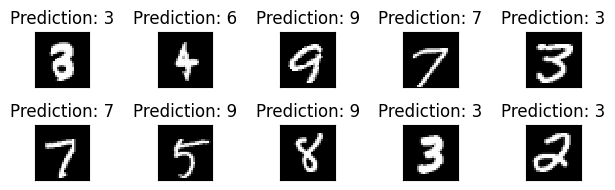

In [10]:
# Run network on data we got before and show predictions
output = model(example_data)

fig = plt.figure()
for i in range(10):
  plt.subplot(5,5,i+1)
  plt.tight_layout()
  plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
  plt.title("Prediction: {}".format(
    output.data.max(1, keepdim=True)[1][i].item()))
  plt.xticks([])
  plt.yticks([])
plt.show()